# Part 1: SST-2 Data Preparation

## 1.1 Install libraries

## 1.2 Load dataset

In [1]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create folders for saving results
Path("./data/processed").mkdir(parents=True, exist_ok=True)
Path("./outputs/tables").mkdir(parents=True, exist_ok=True)
Path("./outputs/figures").mkdir(parents=True, exist_ok=True)
Path("./models").mkdir(parents=True, exist_ok=True)

# Load SST-2 dataset
dataset = load_dataset("nyu-mll/glue", "sst2")

train_data = dataset["train"]
val_data = dataset["validation"]
test_data = dataset["test"]

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print(train_data[0])

d:\NLP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/glue.py
Retrying in 1s [Retry 1/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/glue.py
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/glue.py
Retrying in 4s [Retry 3/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/glue.py
Retrying in 8s [

Train: 67349
Validation: 872
Test: 1821
{'sentence': 'hide new secretions from the parental units ', 'label': 0, 'idx': 0}


## Class distribution

  Sentiment  Count
0  Negative  29780
1  Positive  37569


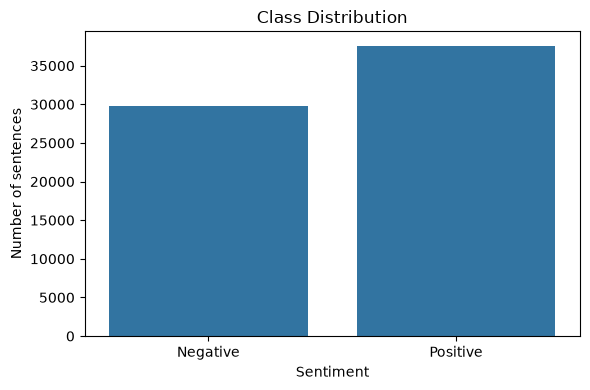

In [2]:
train_df = pd.DataFrame(train_data)

class_counts = train_df["label"].value_counts().sort_index()
class_table = class_counts.rename(index={0: "Negative", 1: "Positive"}).reset_index()
class_table.columns = ["Sentiment", "Count"]

print(class_table)
class_table.to_csv("./outputs/tables/class_distribution.csv", index=False)

plt.figure(figsize=(6, 4))
sns.barplot(data=class_table, x="Sentiment", y="Count")
plt.title("Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of sentences")
plt.tight_layout()
plt.savefig("./outputs/figures/class_distribution.png")
plt.show()

## Sentence length

  Statistic         Value
0     count  67349.000000
1      mean      9.409553
2       std      8.073806
3       min      1.000000
4       25%      3.000000
5       50%      7.000000
6       75%     13.000000
7       max     52.000000


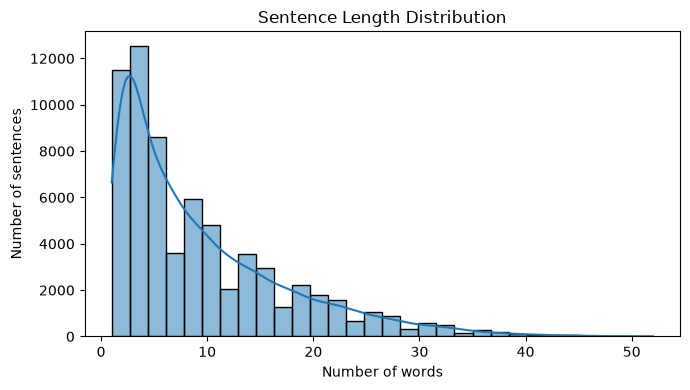

In [3]:
train_df["sentence_length"] = train_df["sentence"].apply(
    lambda sentence: len(sentence.split())
)

length_stats = train_df["sentence_length"].describe().reset_index()
length_stats.columns = ["Statistic", "Value"]

print(length_stats)
length_stats.to_csv("./outputs/tables/sentence_length_statistics.csv", index=False)

plt.figure(figsize=(7, 4))
sns.histplot(train_df["sentence_length"], bins=30, kde=True)
plt.title("Sentence Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of sentences")
plt.tight_layout()
plt.savefig("./outputs/figures/sentence_length_distribution.png")
plt.show()

## Sample sentences

In [4]:
negative_samples = train_df[train_df["label"] == 0].sample(10, random_state=42)
positive_samples = train_df[train_df["label"] == 1].sample(10, random_state=42)

print("10 Negative sentences:")
for sentence in negative_samples["sentence"]:
    print("-", sentence)

print("\n10 Positive sentences:")
for sentence in positive_samples["sentence"]:
    print("-", sentence)

samples = pd.concat([negative_samples, positive_samples])
samples[["sentence", "label"]].to_csv(
    "./outputs/tables/sample_sentences.csv", index=False
)

10 Negative sentences:
- a dull , dumb and derivative horror 
- if george romero had directed this movie , it would n't have taken the protagonists a full hour to determine that in order to kill a zombie you must shoot it in the head 
- the acting is amateurish , the cinematography is atrocious 
- maudlin ending 
- derailed 
- what madonna does here ca n't properly be called acting -- more accurately , it 's moving and it 's talking and it 's occasionally gesturing , sometimes all at once 
- no worse a film 
- loosely connected characters and plots that never quite gel 
- we really have n't had a good cheesy b-movie playing in theaters since ... well ... since last week 's reign of fire 
- horrible '' and `` terrible 

10 Positive sentences:
- acted meditation on both the profoundly devastating events of one year ago and the slow , painful healing process that has followed in their wake 
- this odd , poetic road movie , spiked by jolts of pop music , pretty much takes place in morton '

## Dataset challenges

In [5]:
# Examples of common sentiment analysis challenges
challenges = {
    "Negation": "The movie was not good.",
    "Sarcasm": "What a wonderful way to waste two hours!",
    "Neutral statement": "The movie is two hours long."
}

for challenge, sentence in challenges.items():
    print(challenge + ":", sentence)

Negation: The movie was not good.
Sarcasm: What a wonderful way to waste two hours!
Neutral statement: The movie is two hours long.


## 1.3 BERT tokenization

In [7]:
from transformers import AutoTokenizer

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded")

Tokenizer loaded


## Check sequence lengths

In [8]:
sample_sentence = train_data[0]["sentence"]

for max_length in [128, 256, 512]:
    encoded = tokenizer(
        sample_sentence,
        padding="max_length",
        truncation=True,
        max_length=max_length
    )
    print("Maximum length:", max_length)
    print("Token IDs:", len(encoded["input_ids"]))

Maximum length: 128
Token IDs: 128
Maximum length: 256
Token IDs: 256
Maximum length: 512
Token IDs: 512


## Tokenize and save processed data

In [9]:
max_length = 128

def tokenize_data(examples):
    return tokenizer(
        examples["sentence"],
        padding="max_length",
        truncation=True,
        max_length=max_length
    )

tokenized_train = train_data.map(tokenize_data, batched=True)
tokenized_val = val_data.map(tokenize_data, batched=True)
tokenized_test = test_data.map(tokenize_data, batched=True)

# Save tokenized datasets
tokenized_train.save_to_disk("./data/processed/train")
tokenized_val.save_to_disk("./data/processed/validation")
tokenized_test.save_to_disk("./data/processed/test")

# Save tokenizer files for later use
tokenizer.save_pretrained("./models/bert-base-uncased")

print("Processed datasets saved in ./data/processed")
print("Tokenizer saved in ./models/bert-base-uncased")

Saving the dataset (1/1 shards): 100%|██████████| 1821/1821 [00:00<00:00, 77428.20 examples/s]

Processed datasets saved in ./data/processed
Tokenizer saved in ./models/bert-base-uncased


## Saved files

In [10]:
print("Processed data: ./data/processed/")
print("Tables: ./outputs/tables/")
print("Figures: ./outputs/figures/")
print("Tokenizer: ./models/bert-base-uncased/")

Processed data: ./data/processed/
Tables: ./outputs/tables/
Figures: ./outputs/figures/
Tokenizer: ./models/bert-base-uncased/


# Part 2: BERT Fine-tuning

## 2.1 Load pre-trained BERT

In [11]:
import torch
from datasets import load_from_disk
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create folders
Path("./models").mkdir(parents=True, exist_ok=True)
Path("./outputs/tables").mkdir(parents=True, exist_ok=True)
Path("./outputs/figures").mkdir(parents=True, exist_ok=True)

model_name = "bert-base-uncased"

# Load tokenizer and BERT model
tokenizer = BertTokenizer.from_pretrained(model_name)
model = BertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("BERT model loaded")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 226.21it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoin

BERT model loaded


## 2.2 Load and tokenize data

In [12]:
# Load the processed datasets from Part 1
train_data = load_from_disk("./data/processed/train")
val_data = load_from_disk("./data/processed/validation")

# SST-2 test labels are hidden (-1), so use validation data for evaluation.
# The test split can be used later to create predictions.

def tokenize_function(examples):
    return tokenizer(
        examples["sentence"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_train = train_data.map(tokenize_function, batched=True)
tokenized_val = val_data.map(tokenize_function, batched=True)

# Keep only columns needed by the model
tokenized_train = tokenized_train.remove_columns(["sentence", "idx"])
tokenized_val = tokenized_val.remove_columns(["sentence", "idx"])

tokenized_train.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)
tokenized_val.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

print("Training and validation data are ready")

Training and validation data are ready


## 2.3 Training configuration

In [13]:
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    warmup_steps=500,
    weight_decay=0.01,
    learning_rate=2e-5,
    logging_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none"
)

print("Training configuration created")

Training configuration created


## 2.4 Define evaluation metrics

In [14]:
def compute_metrics(pred):
    labels = pred.label_ids
    predictions = pred.predictions.argmax(-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

## 2.5 Train and evaluate

In [15]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

# Train BERT
train_output = trainer.train()

# Evaluate on validation data
results = trainer.evaluate(tokenized_val)

print(results)

# Save evaluation results
results_df = pd.DataFrame([results])
results_df.to_csv("./outputs/tables/bert_evaluation_results.csv", index=False)

# Save the fine-tuned model and tokenizer
trainer.save_model("./models/bert-finetuned")
tokenizer.save_pretrained("./models/bert-finetuned")

print("Model saved in ./models/bert-finetuned")

Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.167665,0.255104,0.923165,0.925307,0.916115,0.934685
2,0.111670,0.304492,0.917431,0.921739,0.890756,0.954955
3,0.073845,0.331702,0.931193,0.932735,0.928571,0.936937


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.04it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'ber

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.073845,0.331702,3,0.931193,0.932735,0.928571,0.936937


{'eval_loss': 0.3317021429538727, 'eval_accuracy': 0.9311926605504587, 'eval_f1': 0.9327354260089686, 'eval_precision': 0.9285714285714286, 'eval_recall': 0.9369369369369369}


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.10s/it]

Model saved in ./models/bert-finetuned


## Training results

In [16]:
# Display training and validation metrics
metrics_to_show = {
    "Accuracy": results.get("eval_accuracy"),
    "Precision": results.get("eval_precision"),
    "Recall": results.get("eval_recall"),
    "F1 Score": results.get("eval_f1")
}

for metric, value in metrics_to_show.items():
    print(metric + ":", value)

Accuracy: 0.9311926605504587
Precision: 0.9285714285714286
Recall: 0.9369369369369369
F1 Score: 0.9327354260089686


## 2.6 Hyperparameter experiments

The code below compares each setting with a baseline. It runs one experiment for each listed value while keeping the other settings fixed. This can take a long time, especially on a CPU. Set `RUN_EXPERIMENTS` to `True` when ready.

In [17]:
# Baseline settings
baseline = {
    "learning_rate": 2e-5,
    "batch_size": 16,
    "epochs": 3,
    "max_length": 128,
    "warmup_steps": 500
}

# Values to test
experiment_values = {
    "learning_rate": [1e-5, 2e-5, 3e-5, 5e-5],
    "batch_size": [8, 16, 32],
    "epochs": [2, 3, 4, 5],
    "max_length": [128, 256, 512],
    "warmup_steps": [0, 500, 1000]
}

# Set to True to run all experiments
RUN_EXPERIMENTS = False

In [18]:
def prepare_data(max_length):
    # Tokenize data for the selected maximum length
    def tokenize_function(examples):
        return tokenizer(
            examples["sentence"],
            padding="max_length",
            truncation=True,
            max_length=max_length
        )

    train_tokens = train_data.map(tokenize_function, batched=True)
    val_tokens = val_data.map(tokenize_function, batched=True)

    train_tokens = train_tokens.remove_columns(["sentence", "idx"])
    val_tokens = val_tokens.remove_columns(["sentence", "idx"])

    train_tokens.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"]
    )
    val_tokens.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"]
    )

    return train_tokens, val_tokens


def run_experiment(settings):
    # Prepare data for this sequence length
    train_tokens, val_tokens = prepare_data(settings["max_length"])

    # Load a fresh BERT model for each experiment
    experiment_model = BertForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2
    )

    args = TrainingArguments(
        output_dir="./results/hyperparameter_test",
        num_train_epochs=settings["epochs"],
        per_device_train_batch_size=settings["batch_size"],
        per_device_eval_batch_size=64,
        warmup_steps=settings["warmup_steps"],
        weight_decay=0.01,
        learning_rate=settings["learning_rate"],
        logging_steps=100,
        eval_strategy="epoch",
        save_strategy="no",
        report_to="none"
    )

    experiment_trainer = Trainer(
        model=experiment_model,
        args=args,
        train_dataset=train_tokens,
        eval_dataset=val_tokens,
        compute_metrics=compute_metrics
    )

    # Measure training time
    import time
    start_time = time.time()

    experiment_trainer.train()
    scores = experiment_trainer.evaluate()

    training_time = time.time() - start_time

    return {
        **settings,
        "accuracy": scores["eval_accuracy"],
        "precision": scores["eval_precision"],
        "recall": scores["eval_recall"],
        "f1": scores["eval_f1"],
        "training_time_seconds": training_time
    }

In [19]:
if RUN_EXPERIMENTS:
    experiment_results = []

    # Test every value for one parameter at a time
    for parameter, values in experiment_values.items():
        for value in values:
            settings = baseline.copy()
            settings[parameter] = value

            print("Running:", parameter, "=", value)
            result = run_experiment(settings)
            result["changed_parameter"] = parameter
            result["tested_value"] = value
            experiment_results.append(result)

    experiment_df = pd.DataFrame(experiment_results)
    experiment_df.to_csv(
        "./outputs/tables/hyperparameter_results.csv",
        index=False
    )

    print(experiment_df)
else:
    print("Experiments are not running. Set RUN_EXPERIMENTS = True to start.")

Experiments are not running. Set RUN_EXPERIMENTS = True to start.


## Compare hyperparameter results

In [20]:
# Run this cell after the experiments finish
if Path("./outputs/tables/hyperparameter_results.csv").exists():
    experiment_df = pd.read_csv(
        "./outputs/tables/hyperparameter_results.csv"
    )

    print(experiment_df.sort_values("accuracy", ascending=False))

    plt.figure(figsize=(9, 5))
    plt.bar(
        range(len(experiment_df)),
        experiment_df["accuracy"]
    )
    plt.title("Hyperparameter Experiment Accuracy")
    plt.xlabel("Experiment")
    plt.ylabel("Validation Accuracy")
    plt.tight_layout()
    plt.savefig("./outputs/figures/hyperparameter_accuracy.png")
    plt.show()
else:
    print("Run the hyperparameter experiments first.")

Run the hyperparameter experiments first.


## Notes

- The SST-2 test split has hidden labels, so validation data is used for evaluation and hyperparameter selection.
- The hyperparameter cell runs 17 one-parameter-at-a-time experiments. It may take a long time.
- The best settings can be selected from `./outputs/tables/hyperparameter_results.csv`.
- The fine-tuned model is saved in `./models/bert-finetuned/`.

# Part 3: Compare Transformer Architectures

## 3.1 Fine-tune DistilBERT

In [21]:
import time
import pandas as pd
import torch
from pathlib import Path
from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    RobertaTokenizer,
    RobertaForSequenceClassification,
    TrainingArguments,
    Trainer
)

Path("./models").mkdir(parents=True, exist_ok=True)
Path("./outputs/tables").mkdir(parents=True, exist_ok=True)
Path("./outputs/figures").mkdir(parents=True, exist_ok=True)

# Use the same training and validation data from Part 1
max_length = 128

def prepare_model_data(model_tokenizer):
    def tokenize_function(examples):
        return model_tokenizer(
            examples["sentence"],
            padding="max_length",
            truncation=True,
            max_length=max_length
        )

    train_tokens = train_data.map(tokenize_function, batched=True)
    val_tokens = val_data.map(tokenize_function, batched=True)

    # Remove text columns that are not used by the model
    train_tokens = train_tokens.remove_columns(["sentence", "idx"])
    val_tokens = val_tokens.remove_columns(["sentence", "idx"])

    train_tokens.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"]
    )
    val_tokens.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"]
    )

    return train_tokens, val_tokens


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())


def train_and_compare(model, model_tokenizer, model_name, save_path):
    train_tokens, val_tokens = prepare_model_data(model_tokenizer)

    args = TrainingArguments(
        output_dir="./results/" + model_name,
        num_train_epochs=3,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=64,
        learning_rate=2e-5,
        warmup_steps=500,
        weight_decay=0.01,
        logging_steps=100,
        eval_strategy="epoch",
        save_strategy="no",
        report_to="none"
    )

    model_trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_tokens,
        eval_dataset=val_tokens,
        compute_metrics=compute_metrics
    )

    # Measure training time
    start_time = time.time()
    model_trainer.train()
    training_time = time.time() - start_time

    # Measure inference time for up to 1000 validation samples
    small_val_data = val_tokens.select(range(min(1000, len(val_tokens))))

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.time()
    model_trainer.predict(small_val_data)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inference_time = time.time() - start_time

    scores = model_trainer.evaluate()
    parameters = count_parameters(model)

    # Save model and tokenizer
    model_trainer.save_model(save_path)
    model_tokenizer.save_pretrained(save_path)

    result = {
        "Model": model_name,
        "Parameters (M)": round(parameters / 1000000, 2),
        "Accuracy": scores["eval_accuracy"],
        "F1-Score": scores["eval_f1"],
        "Training Time (min)": round(training_time / 60, 2),
        "Inference Time (sec, up to 1000 samples)": round(inference_time, 2)
    }

    return result

In [22]:
# Load DistilBERT
distilbert_name = "distilbert-base-uncased"

distilbert_tokenizer = DistilBertTokenizer.from_pretrained(distilbert_name)
distilbert_model = DistilBertForSequenceClassification.from_pretrained(
    distilbert_name,
    num_labels=2
)

# Fine-tune DistilBERT
distilbert_result = train_and_compare(
    distilbert_model,
    distilbert_tokenizer,
    "DistilBERT",
    "./models/distilbert-finetuned"
)

print(distilbert_result)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 300.85it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 872/872 [00:00<00:00, 9470.65 examples/s]


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.180839,0.345179,0.892202,0.894619,0.890625,0.898649
2,0.119464,0.362064,0.901376,0.905702,0.882479,0.930180
3,0.087406,0.432772,0.902523,0.905660,0.892779,0.918919


Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.087406,0.432772,3,0.902523,0.905660,0.892779,0.918919


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.61it/s]

{'Model': 'DistilBERT', 'Parameters (M)': 66.96, 'Accuracy': 0.9025229357798165, 'F1-Score': 0.9056603773584906, 'Training Time (min)': 36.65, 'Inference Time (sec, up to 1000 samples)': 2.58}


## 3.2 Fine-tune RoBERTa

In [23]:
# Load RoBERTa
roberta_name = "roberta-base"

roberta_tokenizer = RobertaTokenizer.from_pretrained(roberta_name)
roberta_model = RobertaForSequenceClassification.from_pretrained(
    roberta_name,
    num_labels=2
)

# Fine-tune RoBERTa
roberta_result = train_and_compare(
    roberta_model,
    roberta_tokenizer,
    "RoBERTa",
    "./models/roberta-finetuned"
)

print(roberta_result)

Could not reach the Hub ([Errno 11001] getaddrinfo failed). Using cached commit hash for 'roberta-base'.
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/api/models/roberta-base/tree/main/additional_chat_templates
Retrying in 1s [Retry 1/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/api/models/roberta-base/tree/main/additional_chat_templates
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/api/models/roberta-base/tree/main/additional_chat_templates
Retrying in 4s [Retry 3/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/api/models/roberta-base/tree/main/additional_chat_templates
Retrying in 8s [Retry 4/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/api/models/roberta-base/tree/main/additional_chat_templates
Retrying in 8s [Retry 5/5].
'[Errno 11001] getaddrinf

Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,0.200926,0.220712,0.936927,0.938410,0.933185,0.943694
2,0.133864,0.301796,0.928899,0.931264,0.917031,0.945946
3,0.110656,0.300588,0.934633,0.936737,0.923414,0.950450


Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
0.110656,0.300588,3,0.934633,0.936737,0.923414,0.950450


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.04s/it]

{'Model': 'RoBERTa', 'Parameters (M)': 124.65, 'Accuracy': 0.9346330275229358, 'F1-Score': 0.9367369589345172, 'Training Time (min)': 66.35, 'Inference Time (sec, up to 1000 samples)': 5.09}


## 3.3 Optional: ALBERT or ELECTRA

In [24]:
# Optional ALBERT experiment
# Uncomment and run these lines if you want to try ALBERT.

# from transformers import AlbertTokenizer, AlbertForSequenceClassification
#
# albert_name = "albert-base-v2"
# albert_tokenizer = AlbertTokenizer.from_pretrained(albert_name)
# albert_model = AlbertForSequenceClassification.from_pretrained(
#     albert_name,
#     num_labels=2
# )
#
# albert_result = train_and_compare(
#     albert_model,
#     albert_tokenizer,
#     "ALBERT",
#     "./models/albert-finetuned"
# )

## 3.4 Compare model performance

In [25]:
# Add the BERT result from Part 2, if it is available
comparison_results = []

if "results" in globals() and "eval_accuracy" in results:
    bert_parameters = 109.5  # Approximate BERT-base parameter count in millions

    comparison_results.append({
        "Model": "BERT-base",
        "Parameters (M)": bert_parameters,
        "Accuracy": results.get("eval_accuracy"),
        "F1-Score": results.get("eval_f1"),
        "Training Time (min)": (
            round(train_output.metrics["train_runtime"] / 60, 2)
            if "train_output" in globals() else None
        ),
        "Inference Time (sec, up to 1000 samples)": None
    })

comparison_results.append(distilbert_result)
comparison_results.append(roberta_result)

comparison_df = pd.DataFrame(comparison_results)
print(comparison_df)

comparison_df.to_csv(
    "./outputs/tables/transformer_comparison.csv",
    index=False
)

        Model  Parameters (M)  Accuracy  F1-Score  Training Time (min)  \
0   BERT-base          109.50  0.931193  0.932735                67.97   
1  DistilBERT           66.96  0.902523  0.905660                36.65   
2     RoBERTa          124.65  0.934633  0.936737                66.35   

   Inference Time (sec, up to 1000 samples)  
0                                       NaN  
1                                      2.58  
2                                      5.09  


## Compare accuracy and training time

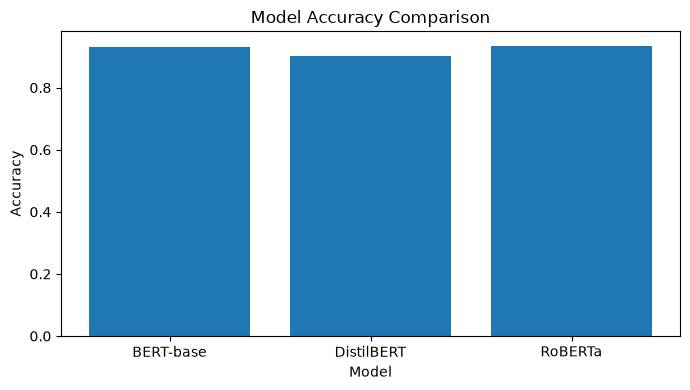

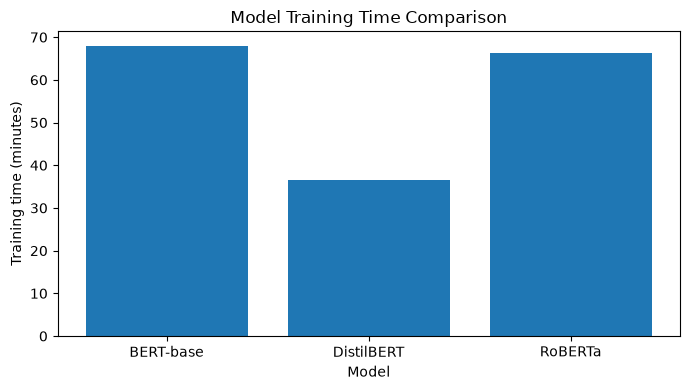

In [26]:
# Plot model accuracy
plt.figure(figsize=(7, 4))
plt.bar(comparison_df["Model"], comparison_df["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.savefig("./outputs/figures/model_accuracy_comparison.png")
plt.show()

# Plot training time
plt.figure(figsize=(7, 4))
plt.bar(
    comparison_df["Model"],
    comparison_df["Training Time (min)"]
)
plt.title("Model Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training time (minutes)")
plt.tight_layout()
plt.savefig("./outputs/figures/model_training_time_comparison.png")
plt.show()

## LSTM comparison

Add the Assignment 5 LSTM results to the comparison table when available. The values should come from your actual LSTM experiment; they are not filled with estimated scores.

Example:

```python
lstm_result = {
    "Model": "LSTM (Assignment 5)",
    "Parameters (M)": 0,  # Replace with actual parameter count in millions
    "Accuracy": 0,        # Replace with actual accuracy
    "F1-Score": 0,         # Replace with actual F1 score
    "Training Time (min)": 0,
    "Inference Time (sec, up to 1000 samples)": 0
}

comparison_df = pd.concat(
    [comparison_df, pd.DataFrame([lstm_result])],
    ignore_index=True
)
comparison_df.to_csv(
    "./outputs/tables/transformer_comparison.csv",
    index=False
)
```

The table reports measured training and inference time on the computer used to run the notebook. Results can vary depending on CPU/GPU hardware. The BERT inference time is left blank unless measured separately.

# Part 4: Attention Visualization

## 4.1 Extract attention weights

In [27]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import BertTokenizer, BertForSequenceClassification
from pathlib import Path

Path("./outputs/figures").mkdir(parents=True, exist_ok=True)

# Load the fine-tuned BERT model from Part 2
model_path = "./models/bert-finetuned"

try:
    tokenizer = BertTokenizer.from_pretrained(model_path)
    model = BertForSequenceClassification.from_pretrained(
        model_path,
        output_attentions=True
    )
except:
    # Use the pre-trained BERT model if the fine-tuned model is not available
    tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
    model = BertForSequenceClassification.from_pretrained(
        "bert-base-uncased",
        num_labels=2,
        output_attentions=True
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

print("Model loaded on:", device)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 231.52it/s]


Model loaded on: cuda


## 4.2 Visualize self-attention

In [28]:
# Example sentence with a negation and sentiment word
sample_sentence = "The movie was not excellent, but the ending was wonderful."

# Tokenize the sentence
inputs = tokenizer(
    sample_sentence,
    return_tensors="pt",
    truncation=True,
    max_length=128
)

# Move input tensors to the model device
inputs = {key: value.to(device) for key, value in inputs.items()}

# Get attention weights
with torch.no_grad():
    outputs = model(**inputs)

attentions = outputs.attentions
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].cpu().tolist()
)

print("Number of attention layers:", len(attentions))
print("Number of attention heads in first layer:", attentions[0].shape[1])
print("Tokens:", tokens)

Number of attention layers: 12
Number of attention heads in first layer: 12
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'excellent', ',', 'but', 'the', 'ending', 'was', 'wonderful', '.', '[SEP]']


## Last layer attention heatmap

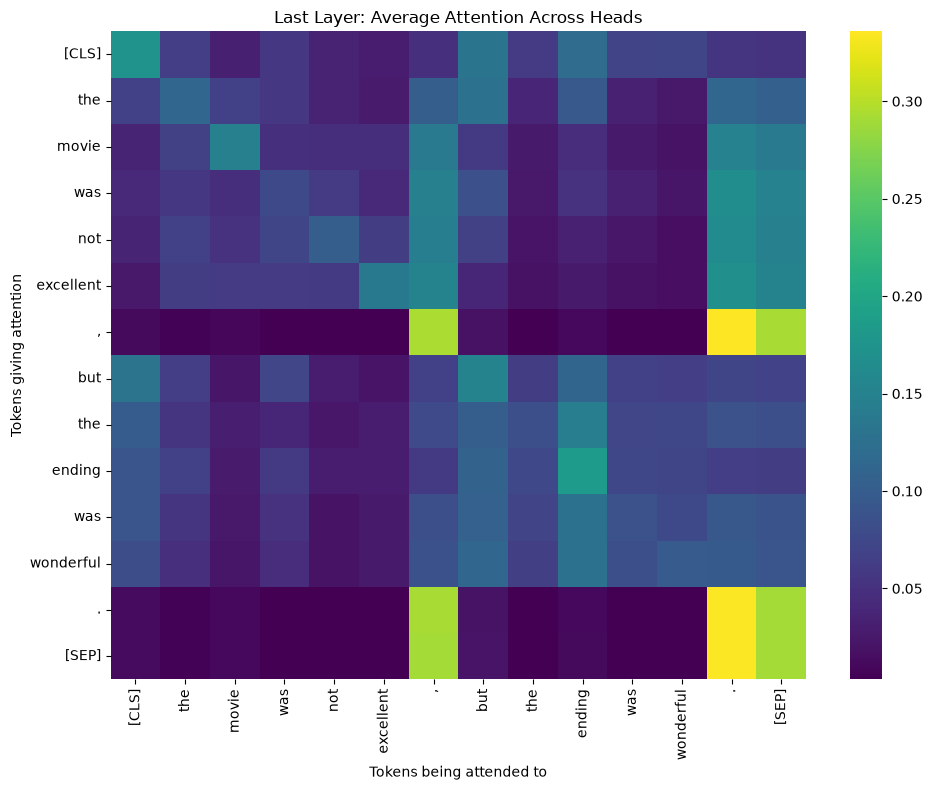

In [29]:
# Get attention from the last layer
# Shape: (number of heads, tokens, tokens)
last_layer_attention = attentions[-1][0].cpu().numpy()

# Average attention across all heads
average_attention = last_layer_attention.mean(axis=0)

plt.figure(figsize=(10, 8))
sns.heatmap(
    average_attention,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)
plt.title("Last Layer: Average Attention Across Heads")
plt.xlabel("Tokens being attended to")
plt.ylabel("Tokens giving attention")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("./outputs/figures/bert_last_layer_attention.png")
plt.show()

## Attention head analysis

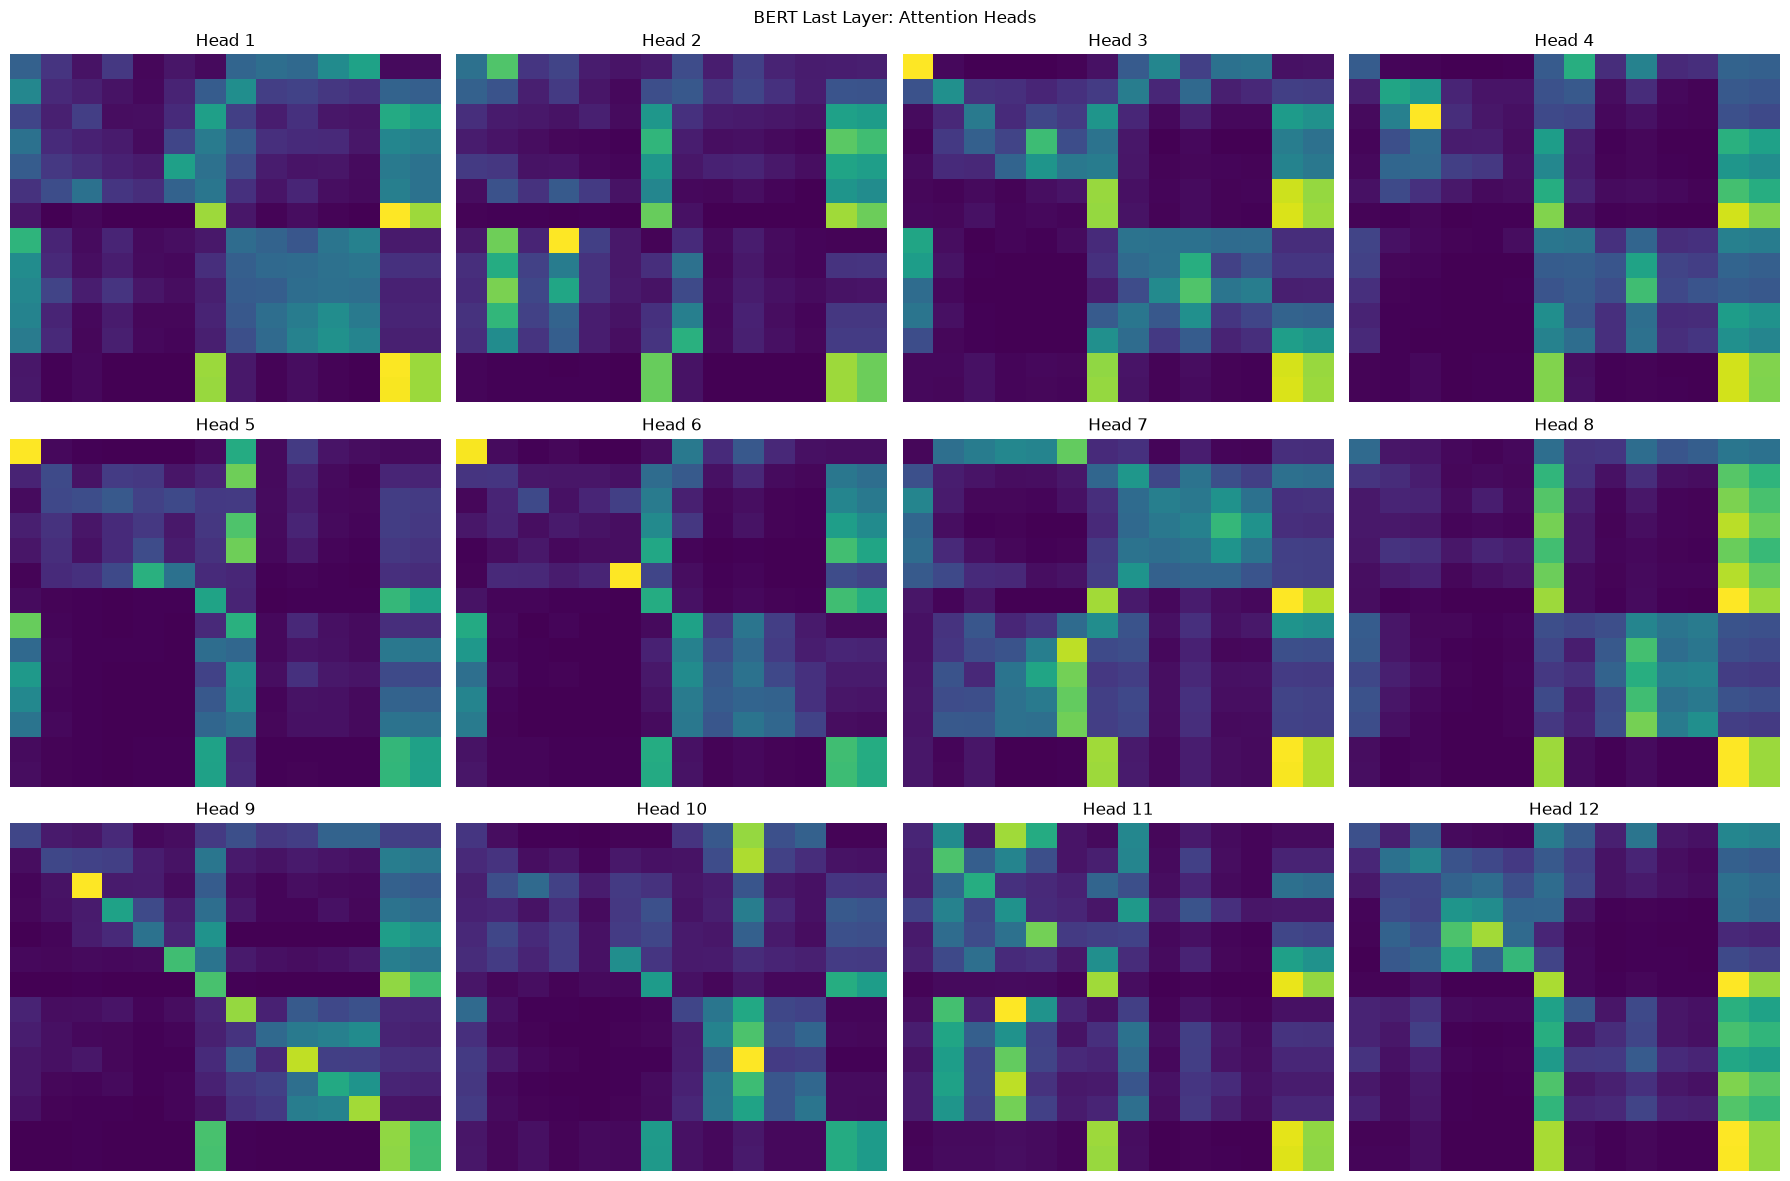

In [30]:
# Display all 12 attention heads from the last layer
number_of_heads = last_layer_attention.shape[0]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))

for head in range(number_of_heads):
    row = head // 4
    column = head % 4

    sns.heatmap(
        last_layer_attention[head],
        ax=axes[row, column],
        cmap="viridis",
        cbar=False
    )
    axes[row, column].set_title("Head " + str(head + 1))
    axes[row, column].set_xticks([])
    axes[row, column].set_yticks([])

plt.suptitle("BERT Last Layer: Attention Heads")
plt.tight_layout()
plt.savefig("./outputs/figures/bert_attention_heads.png")
plt.show()

## Multi-head attention patterns

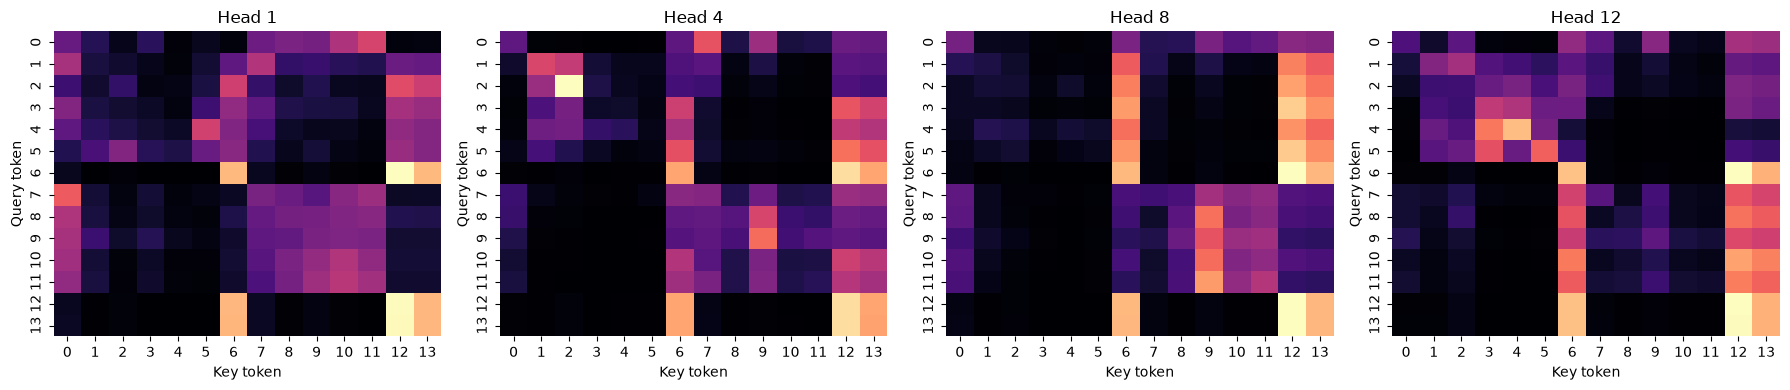

In [31]:
# Compare a few attention heads
selected_heads = [0, 3, 7, 11]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for i, head in enumerate(selected_heads):
    sns.heatmap(
        last_layer_attention[head],
        ax=axes[i],
        cmap="magma",
        cbar=False
    )
    axes[i].set_title("Head " + str(head + 1))
    axes[i].set_xlabel("Key token")
    axes[i].set_ylabel("Query token")

plt.tight_layout()
plt.savefig("./outputs/figures/bert_selected_attention_heads.png")
plt.show()

## 4.3 Interpret attention patterns

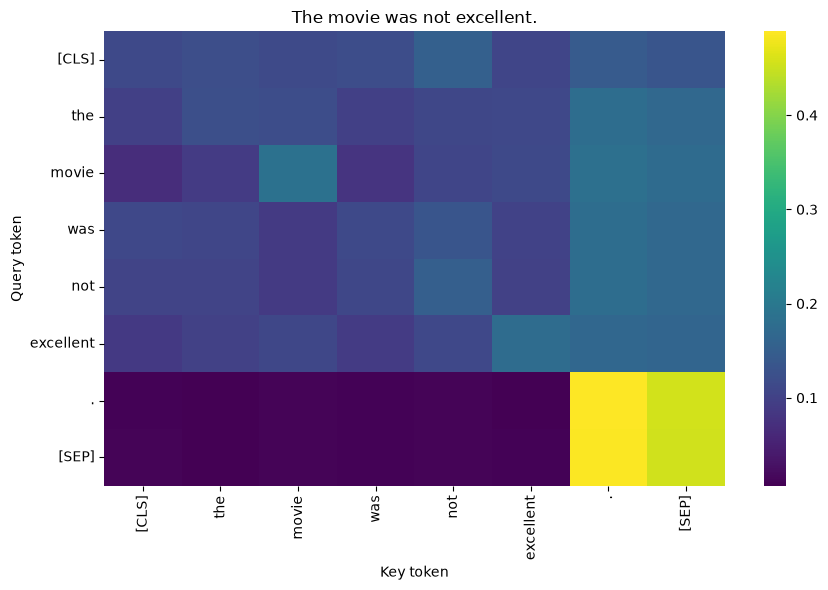

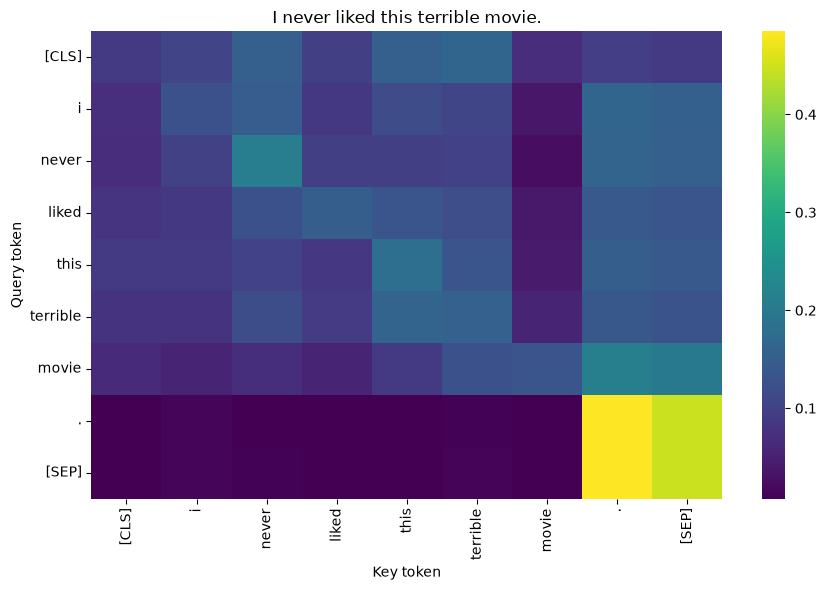

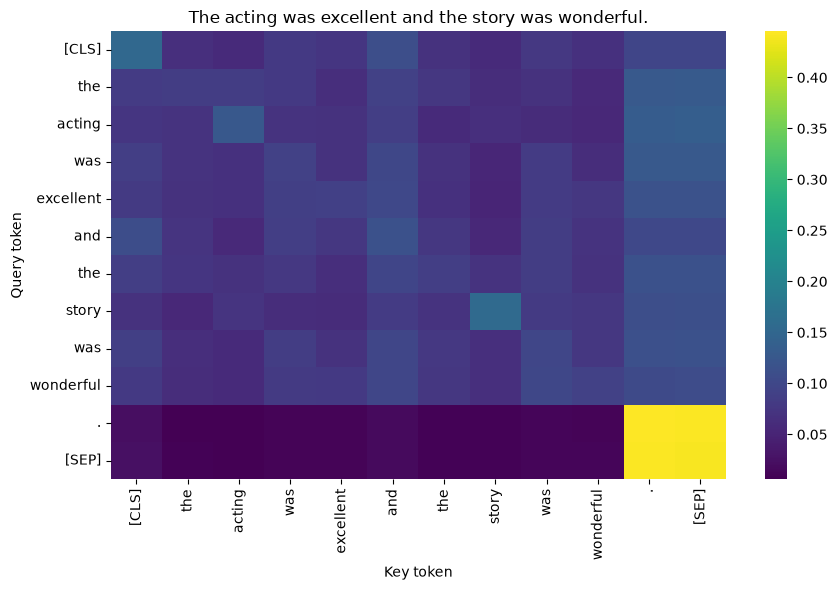

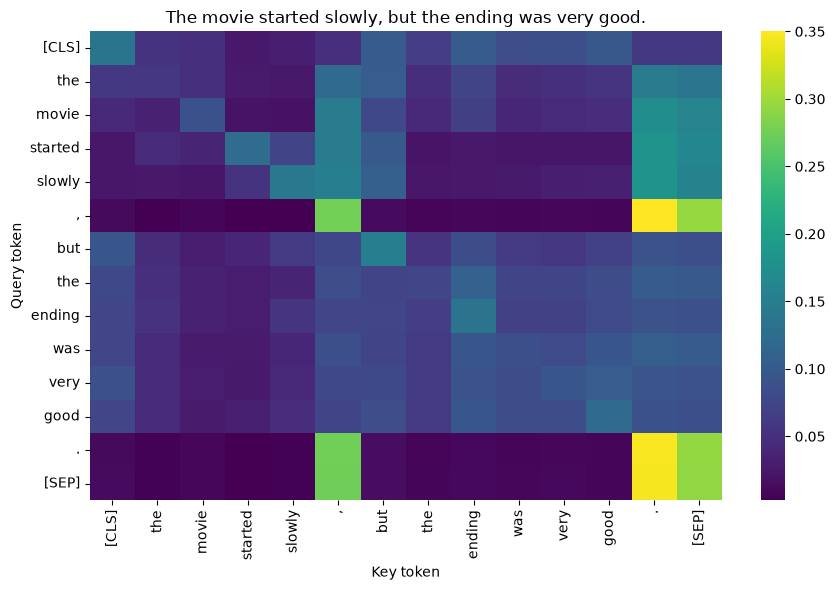

In [32]:
# Try sentences with negation and sentiment words
sample_sentences = [
    "The movie was not excellent.",
    "I never liked this terrible movie.",
    "The acting was excellent and the story was wonderful.",
    "The movie started slowly, but the ending was very good."
]

for sentence in sample_sentences:
    sample_inputs = tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )
    sample_inputs = {
        key: value.to(device) for key, value in sample_inputs.items()
    }

    with torch.no_grad():
        sample_outputs = model(**sample_inputs)

    sample_tokens = tokenizer.convert_ids_to_tokens(
        sample_inputs["input_ids"][0].cpu().tolist()
    )
    sample_attention = sample_outputs.attentions[-1][0].mean(dim=0).cpu().numpy()

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        sample_attention,
        xticklabels=sample_tokens,
        yticklabels=sample_tokens,
        cmap="viridis"
    )
    plt.title(sentence)
    plt.xlabel("Key token")
    plt.ylabel("Query token")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()

    safe_name = "attention_" + str(sample_sentences.index(sentence) + 1)
    plt.savefig("./outputs/figures/" + safe_name + ".png")
    plt.show()

### Attention observations

Use the generated heatmaps to write down what you notice.

- Check whether the words **not** and **never** attend to nearby sentiment words.
- Check how words such as **excellent** and **terrible** attend to other tokens.
- Look for attention between words that are far apart in a sentence.
- Compare different heads. Some heads may show local patterns, while others may focus on words farther away.

Attention weights show where a model places attention, but they do not always explain why the model made a prediction.

## 4.4 Attention rollout

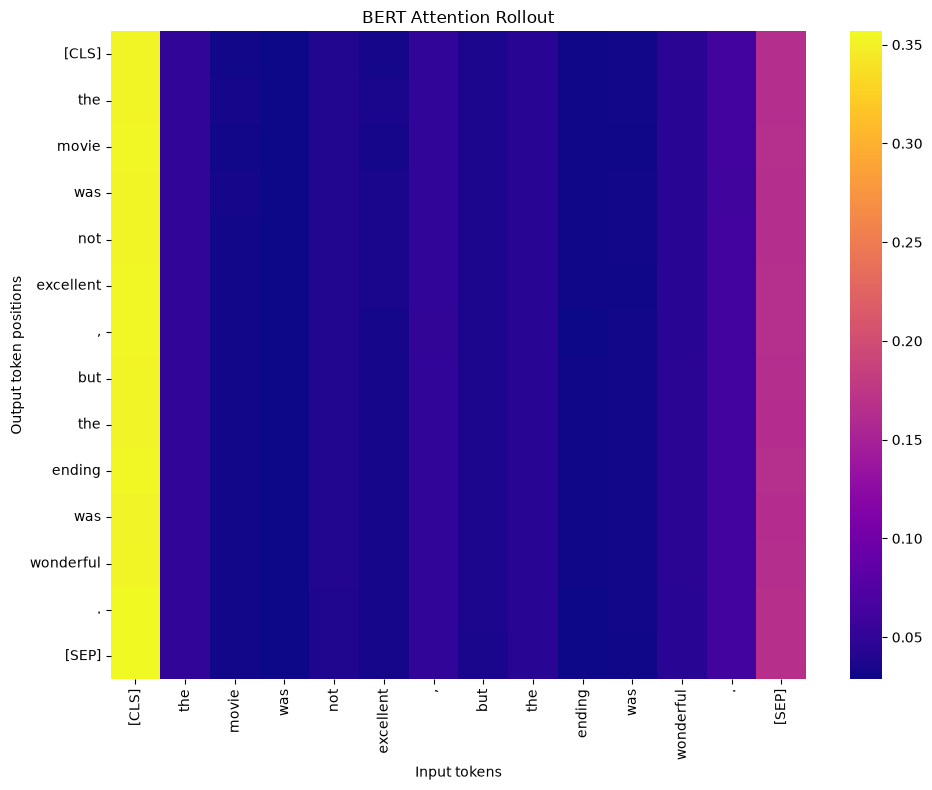

In [33]:
# Attention rollout combines attention information from all layers.
# First average the attention heads in each layer.
attention_matrices = []

for layer_attention in attentions:
    # Shape after averaging: (tokens, tokens)
    layer_matrix = layer_attention[0].mean(dim=0).cpu().numpy()

    # Add residual connection
    layer_matrix = layer_matrix + np.eye(layer_matrix.shape[0])

    # Normalize each row
    layer_matrix = layer_matrix / layer_matrix.sum(axis=-1, keepdims=True)

    attention_matrices.append(layer_matrix)

# Multiply attention matrices from all layers
rollout = attention_matrices[0]

for layer_matrix in attention_matrices[1:]:
    rollout = np.matmul(layer_matrix, rollout)

plt.figure(figsize=(10, 8))
sns.heatmap(
    rollout,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="plasma"
)
plt.title("BERT Attention Rollout")
plt.xlabel("Input tokens")
plt.ylabel("Output token positions")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("./outputs/figures/bert_attention_rollout.png")
plt.show()

## Compare attention across models

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 382.10it/s]


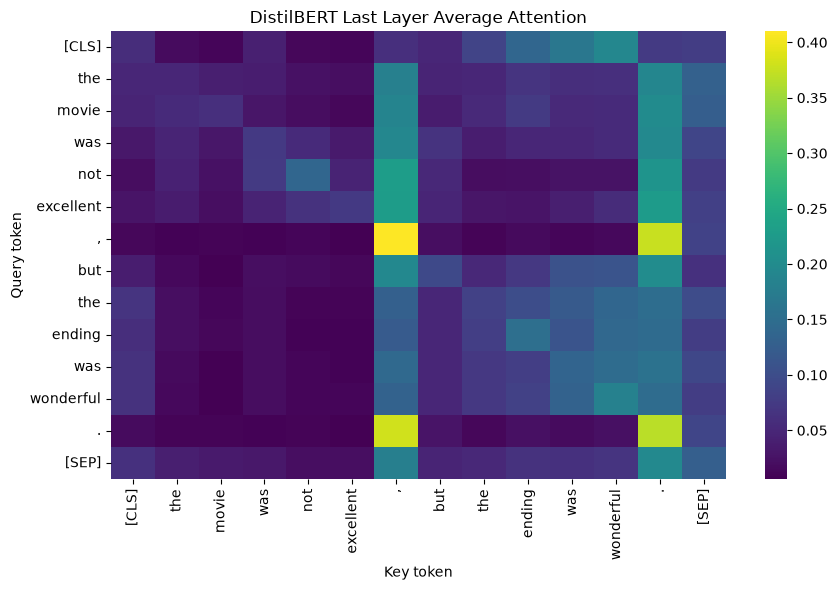

In [34]:
# Optional: load DistilBERT and compare its last-layer average attention.
# Run this cell after Part 3 has trained and saved DistilBERT.

from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

try:
    distil_tokenizer = DistilBertTokenizer.from_pretrained(
        "./models/distilbert-finetuned"
    )
    distil_model = DistilBertForSequenceClassification.from_pretrained(
        "./models/distilbert-finetuned",
        output_attentions=True
    )

    distil_model.to(device)
    distil_model.eval()

    distil_inputs = distil_tokenizer(
        sample_sentence,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )
    distil_inputs = {
        key: value.to(device) for key, value in distil_inputs.items()
    }

    with torch.no_grad():
        distil_outputs = distil_model(**distil_inputs)

    distil_tokens = distil_tokenizer.convert_ids_to_tokens(
        distil_inputs["input_ids"][0].cpu().tolist()
    )
    distil_attention = (
        distil_outputs.attentions[-1][0].mean(dim=0).cpu().numpy()
    )

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        distil_attention,
        xticklabels=distil_tokens,
        yticklabels=distil_tokens,
        cmap="viridis"
    )
    plt.title("DistilBERT Last Layer Average Attention")
    plt.xlabel("Key token")
    plt.ylabel("Query token")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig("./outputs/figures/distilbert_last_layer_attention.png")
    plt.show()

except Exception as error:
    print("DistilBERT model not found or could not be loaded.")
    print("Run Part 3 first. Details:", error)

## Compare BERT and DistilBERT

The BERT and DistilBERT heatmaps can be compared for the same sentence. The models have different numbers of layers and attention heads, so their patterns may look different. Use the figures to describe any visible differences.

RoBERTa attention can also be visualized by loading its saved model and tokenizer in the same way, using `RobertaTokenizer` and `RobertaForSequenceClassification` with `output_attentions=True`.

## Saved figures

All attention visualizations are saved in `./outputs/figures/`.

# Part 5: Advanced Techniques

## 5.1 Layer-wise learning rate decay

In [35]:
import torch
from transformers import Trainer, TrainingArguments, BertForSequenceClassification
from pathlib import Path
import pandas as pd
import time
import numpy as np

Path("./models").mkdir(parents=True, exist_ok=True)
Path("./outputs/tables").mkdir(parents=True, exist_ok=True)
Path("./outputs/figures").mkdir(parents=True, exist_ok=True)

# Load the fine-tuned BERT model
bert_model = BertForSequenceClassification.from_pretrained(
    "./models/bert-finetuned"
)

# Give different learning rates to different BERT parts
optimizer_grouped_parameters = [
    {
        "params": bert_model.bert.embeddings.parameters(),
        "lr": 1e-5
    },
    {
        "params": bert_model.bert.encoder.layer[:6].parameters(),
        "lr": 2e-5
    },
    {
        "params": bert_model.bert.encoder.layer[6:].parameters(),
        "lr": 3e-5
    },
    {
        "params": bert_model.classifier.parameters(),
        "lr": 5e-5
    }
]

# Create an optimizer with the selected learning rates
layer_optimizer = torch.optim.AdamW(
    optimizer_grouped_parameters,
    weight_decay=0.01
)

print("Layer-wise optimizer created")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 300.27it/s]

Layer-wise optimizer created


### Train using layer-wise learning rates

In [ ]:
# Pass the custom optimizer to Trainer so these learning rates are used
layer_args = TrainingArguments(
    output_dir="./results/layerwise",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

layer_trainer = Trainer(
    model=bert_model,
    args=layer_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    optimizers=(layer_optimizer, None)
)

layer_trainer.train()
layer_trainer.save_model("./models/bert-layerwise")
print("Layer-wise learning rate training completed")

Epoch,Training Loss,Validation Loss


## 5.2 Gradual unfreezing

In [ ]:
# Load a fresh BERT model
gradual_model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

# First, freeze embeddings and the lower six layers
for parameter in gradual_model.bert.embeddings.parameters():
    parameter.requires_grad = False

for layer in gradual_model.bert.encoder.layer[:6]:
    for parameter in layer.parameters():
        parameter.requires_grad = False

# Train the upper layers and classifier first
gradual_args = TrainingArguments(
    output_dir="./results/gradual_stage1",
    num_train_epochs=1,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

gradual_trainer = Trainer(
    model=gradual_model,
    args=gradual_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

gradual_trainer.train()

# Unfreeze all layers for the second stage
for parameter in gradual_model.parameters():
    parameter.requires_grad = True

gradual_args_stage2 = TrainingArguments(
    output_dir="./results/gradual_stage2",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=1e-5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

gradual_trainer_stage2 = Trainer(
    model=gradual_model,
    args=gradual_args_stage2,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

gradual_trainer_stage2.train()
gradual_trainer_stage2.save_model("./models/bert-gradual-unfreezing")
print("Gradual unfreezing training completed")

## 5.3 Data augmentation

In [ ]:
import random
import nltk
from nltk.corpus import wordnet

# Download WordNet data once
nltk.download("wordnet")
nltk.download("omw-1.4")

def synonym_replacement(sentence):
    words = sentence.split()
    new_words = words.copy()

    for i, word in enumerate(words):
        synonyms = []

        for syn in wordnet.synsets(word):
            for lemma in syn.lemmas():
                synonym = lemma.name().replace("_", " ")
                if synonym.lower() != word.lower():
                    synonyms.append(synonym)

        if synonyms:
            new_words[i] = random.choice(synonyms)
            break

    return " ".join(new_words)


def random_deletion(sentence, probability=0.1):
    words = sentence.split()

    if len(words) <= 2:
        return sentence

    kept_words = [
        word for word in words
        if random.random() > probability
    ]

    if len(kept_words) == 0:
        return random.choice(words)

    return " ".join(kept_words)


# Create a small augmented sample from the training data
augmented_rows = []

for example in train_data.select(range(1000)):
    sentence = example["sentence"]
    label = example["label"]

    augmented_rows.append({
        "sentence": synonym_replacement(sentence),
        "label": label
    })

    augmented_rows.append({
        "sentence": random_deletion(sentence),
        "label": label
    })

augmented_df = pd.DataFrame(augmented_rows)
augmented_df.to_csv(
    "./data/processed/augmented_sample.csv",
    index=False
)

print("Created augmented examples:", len(augmented_df))

### Optional back-translation

In [ ]:
# Back-translation requires downloading translation models.
# This example is optional and may need a GPU and internet connection.

# Uncomment to install:
# !pip install transformers sentencepiece

# from transformers import pipeline
#
# translator_to_french = pipeline(
#     "translation",
#     model="Helsinki-NLP/opus-mt-en-fr"
# )
# translator_to_english = pipeline(
#     "translation",
#     model="Helsinki-NLP/opus-mt-fr-en"
# )
#
# text = "The movie was very enjoyable."
# french_text = translator_to_french(text)[0]["translation_text"]
# back_translated = translator_to_english(french_text)[0]["translation_text"]
# print("Original:", text)
# print("Back-translated:", back_translated)

### Train with augmented data

In [ ]:
# Combine original and augmented training examples
from datasets import Dataset, concatenate_datasets

augmented_dataset = Dataset.from_pandas(augmented_df)

def tokenize_augmented(examples):
    return tokenizer(
        examples["sentence"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

augmented_tokens = augmented_dataset.map(
    tokenize_augmented,
    batched=True
)
augmented_tokens = augmented_tokens.remove_columns(["sentence"])
augmented_tokens.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

combined_train = concatenate_datasets([
    tokenized_train,
    augmented_tokens
])

print("Original training examples:", len(tokenized_train))
print("Training examples with augmentation:", len(combined_train))

# Train BERT using the augmented data
augmented_model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

augmented_args = TrainingArguments(
    output_dir="./results/bert_augmented",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

augmented_trainer = Trainer(
    model=augmented_model,
    args=augmented_args,
    train_dataset=combined_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

augmented_trainer.train()
augmented_results = augmented_trainer.evaluate()

# Save the augmented model and its results
augmented_trainer.save_model("./models/bert-augmented")
tokenizer.save_pretrained("./models/bert-augmented")

comparison = pd.DataFrame([
    {
        "Training data": "Original",
        "Accuracy": results.get("eval_accuracy"),
        "F1-score": results.get("eval_f1")
    },
    {
        "Training data": "Original + augmented",
        "Accuracy": augmented_results.get("eval_accuracy"),
        "F1-score": augmented_results.get("eval_f1")
    }
])

print(comparison)
comparison.to_csv(
    "./outputs/tables/data_augmentation_comparison.csv",
    index=False
)

## 5.4 Ensemble methods

In [ ]:
# Load the three fine-tuned models from Part 2 and Part 3
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from torch.utils.data import DataLoader

model_paths = {
    "BERT": "./models/bert-finetuned",
    "RoBERTa": "./models/roberta-finetuned",
    "DistilBERT": "./models/distilbert-finetuned"
}

# Load validation sentences
validation_sentences = val_data["sentence"]
validation_labels = np.array(val_data["label"])

all_probabilities = []
model_names = []

for name, path in model_paths.items():
    try:
        current_tokenizer = AutoTokenizer.from_pretrained(path)
        current_model = AutoModelForSequenceClassification.from_pretrained(path)
        current_model.to(device)
        current_model.eval()

        batch_probabilities = []

        for start in range(0, len(validation_sentences), 32):
            batch_text = validation_sentences[start:start + 32]
            batch_inputs = current_tokenizer(
                batch_text,
                padding=True,
                truncation=True,
                max_length=128,
                return_tensors="pt"
            )
            batch_inputs = {
                key: value.to(device) for key, value in batch_inputs.items()
            }

            with torch.no_grad():
                logits = current_model(**batch_inputs).logits
                probabilities = torch.softmax(logits, dim=1)

            batch_probabilities.extend(probabilities.cpu().numpy())

        all_probabilities.append(np.array(batch_probabilities))
        model_names.append(name)
        print(name, "predictions completed")

    except Exception as error:
        print(name, "model not available. Run its training cell first.")
        print(error)

if len(all_probabilities) > 0:
    probability_stack = np.stack(all_probabilities)
    individual_predictions = probability_stack.argmax(axis=2)

    # Majority voting
    majority_predictions = []
    for row in individual_predictions.T:
        counts = np.bincount(row, minlength=2)
        majority_predictions.append(np.argmax(counts))

    # Average probability (equal weights)
    average_probabilities = probability_stack.mean(axis=0)
    average_predictions = average_probabilities.argmax(axis=1)

    from sklearn.metrics import accuracy_score, f1_score

    print("Majority vote accuracy:",
          accuracy_score(validation_labels, majority_predictions))
    print("Average probability accuracy:",
          accuracy_score(validation_labels, average_predictions))
else:
    print("Train the models in Parts 2 and 3 before running ensemble.")

### Weighted averaging and stacking

In [ ]:
if len(all_probabilities) > 0:
    # Give equal weights to available models as a simple starting point
    weights = np.ones(len(all_probabilities)) / len(all_probabilities)

    weighted_probabilities = np.average(
        probability_stack,
        axis=0,
        weights=weights
    )
    weighted_predictions = weighted_probabilities.argmax(axis=1)

    print("Weighted average accuracy:",
          accuracy_score(validation_labels, weighted_predictions))

    # Stacking: train a simple meta-model using validation probabilities.
    # For a proper estimate, use a separate held-out set or out-of-fold predictions.
    from sklearn.linear_model import LogisticRegression

    meta_features = probability_stack.transpose(1, 0, 2).reshape(
        len(validation_labels), -1
    )
    meta_model = LogisticRegression(max_iter=1000)
    meta_model.fit(meta_features, validation_labels)
    stacking_predictions = meta_model.predict(meta_features)

    print("Stacking training accuracy:",
          accuracy_score(validation_labels, stacking_predictions))
    print("Note: This stacking score is training accuracy, not an unbiased test score.")

## 5.5 Knowledge distillation

In [ ]:
# Teacher: fine-tuned RoBERTa
# Student: DistilBERT

from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    DistilBertTokenizer,
    DistilBertForSequenceClassification
)
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

teacher_tokenizer = RobertaTokenizer.from_pretrained(
    "./models/roberta-finetuned"
)
teacher_model = RobertaForSequenceClassification.from_pretrained(
    "./models/roberta-finetuned"
).to(device)
teacher_model.eval()

student_tokenizer = DistilBertTokenizer.from_pretrained(
    "distilbert-base-uncased"
)
student_model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
).to(device)

# Keep sentences as text and tokenize one batch at a time
class ReviewDataset(Dataset):
    def __init__(self, data):
        self.sentences = data["sentence"]
        self.labels = data["label"]

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, index):
        return self.sentences[index], self.labels[index]


def prepare_batch(batch):
    sentences = [item[0] for item in batch]
    labels = torch.tensor([item[1] for item in batch])

    teacher_inputs = teacher_tokenizer(
        sentences,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )
    student_inputs = student_tokenizer(
        sentences,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    return teacher_inputs, student_inputs, labels


train_loader = DataLoader(
    ReviewDataset(train_data),
    batch_size=16,
    shuffle=True,
    collate_fn=prepare_batch
)

optimizer = torch.optim.AdamW(
    student_model.parameters(),
    lr=2e-5
)

temperature = 2.0
alpha = 0.5

# Train the student using teacher predictions and true labels
for epoch in range(2):
    student_model.train()
    total_loss = 0

    for teacher_inputs, student_inputs, labels in train_loader:
        teacher_inputs = {
            key: value.to(device) for key, value in teacher_inputs.items()
        }
        student_inputs = {
            key: value.to(device) for key, value in student_inputs.items()
        }
        labels = labels.to(device)

        with torch.no_grad():
            teacher_logits = teacher_model(**teacher_inputs).logits

        student_logits = student_model(**student_inputs).logits

        soft_loss = F.kl_div(
            F.log_softmax(student_logits / temperature, dim=1),
            F.softmax(teacher_logits / temperature, dim=1),
            reduction="batchmean"
        ) * (temperature ** 2)

        hard_loss = F.cross_entropy(student_logits, labels)
        loss = alpha * soft_loss + (1 - alpha) * hard_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print("Epoch", epoch + 1, "loss:", total_loss / len(train_loader))

# Save the trained student model
student_model.save_pretrained("./models/distilbert-distilled")
student_tokenizer.save_pretrained("./models/distilbert-distilled")
print("Student model saved")

### Compare teacher and student

In [ ]:
# Measure accuracy, F1-score and prediction time on validation data
from sklearn.metrics import accuracy_score, f1_score

def evaluate_model(model, model_tokenizer, sentences, true_labels):
    model.eval()
    predictions = []
    start_time = time.time()

    for start in range(0, len(sentences), 32):
        batch_sentences = sentences[start:start + 32]
        inputs = model_tokenizer(
            batch_sentences,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )
        inputs = {key: value.to(device) for key, value in inputs.items()}

        with torch.no_grad():
            logits = model(**inputs).logits

        predictions.extend(logits.argmax(dim=1).cpu().numpy())

    if device.type == "cuda":
        torch.cuda.synchronize()

    prediction_time = time.time() - start_time

    return {
        "Accuracy": accuracy_score(true_labels, predictions),
        "F1-score": f1_score(true_labels, predictions),
        "Inference time (seconds)": round(prediction_time, 2),
        "Parameters (millions)": round(
            sum(p.numel() for p in model.parameters()) / 1000000, 2
        )
    }


teacher_result = evaluate_model(
    teacher_model,
    teacher_tokenizer,
    val_data["sentence"],
    val_data["label"]
)
student_result = evaluate_model(
    student_model,
    student_tokenizer,
    val_data["sentence"],
    val_data["label"]
)

distillation_table = pd.DataFrame([
    {"Model": "RoBERTa teacher", **teacher_result},
    {"Model": "DistilBERT student", **student_result}
])

print(distillation_table)
distillation_table.to_csv(
    "./outputs/tables/knowledge_distillation_comparison.csv",
    index=False
)

## 5.6 Mixed precision training (FP16)

In [ ]:
# FP16 training is supported on suitable NVIDIA GPUs.
# On CPU, keep fp16 disabled.

use_fp16 = torch.cuda.is_available()

fp16_args = TrainingArguments(
    output_dir="./results/bert_fp16",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    warmup_steps=500,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    fp16=use_fp16,
    report_to="none"
)

fp16_model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)

fp16_trainer = Trainer(
    model=fp16_model,
    args=fp16_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

start_time = time.time()
fp16_trainer.train()
fp16_training_time = time.time() - start_time

if torch.cuda.is_available():
    peak_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
else:
    peak_memory_mb = None

fp16_results = fp16_trainer.evaluate()
print("FP16 enabled:", use_fp16)
print("Training time (seconds):", round(fp16_training_time, 2))
print("Peak GPU memory (MB):", peak_memory_mb)
print(fp16_results)

pd.DataFrame([{
    "fp16_enabled": use_fp16,
    "training_time_seconds": fp16_training_time,
    "peak_gpu_memory_mb": peak_memory_mb,
    "accuracy": fp16_results.get("eval_accuracy"),
    "f1": fp16_results.get("eval_f1")
}]).to_csv("./outputs/tables/fp16_results.csv", index=False)

# Part 6: Deployment

## 6.1 Export BERT to ONNX

In [ ]:
# Install ONNX packages if needed
#!pip install onnx onnxruntime

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

deployment_model_path = "./models/bert-finetuned"
deployment_tokenizer = AutoTokenizer.from_pretrained(deployment_model_path)
deployment_model = AutoModelForSequenceClassification.from_pretrained(
    deployment_model_path
)
deployment_model.eval()

sample_inputs = deployment_tokenizer(
    "The movie was excellent.",
    return_tensors="pt"
)

# Export the model to ONNX
torch.onnx.export(
    deployment_model,
    (
        sample_inputs["input_ids"],
        sample_inputs["attention_mask"]
    ),
    "./models/bert-sentiment.onnx",
    input_names=["input_ids", "attention_mask"],
    output_names=["logits"],
    dynamic_axes={
        "input_ids": {0: "batch_size", 1: "sequence_length"},
        "attention_mask": {0: "batch_size", 1: "sequence_length"},
        "logits": {0: "batch_size"}
    },
    opset_version=14
)

print("ONNX model saved to ./models/bert-sentiment.onnx")

## 6.2 Export to TorchScript

In [ ]:
# Trace the model using an example input
class BertForExport(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, input_ids, attention_mask):
        return self.model(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).logits

export_model = BertForExport(deployment_model)
export_model.eval()

traced_model = torch.jit.trace(
    export_model,
    (
        sample_inputs["input_ids"],
        sample_inputs["attention_mask"]
    )
)

traced_model.save("./models/bert-sentiment-torchscript.pt")
print("TorchScript model saved")

## 6.3 Streamlit sentiment app

The following cell creates a separate Python file named `app.py`. Run it from the project folder using `streamlit run app.py`.

In [ ]:
%%writefile app.py
import streamlit as st
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_PATH = "./models/bert-finetuned"

@st.cache_resource
def load_model():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()
    return tokenizer, model, device

st.title("Movie Review Sentiment Analysis")
st.write("Enter a sentence to predict whether its sentiment is positive or negative.")

tokenizer, model, device = load_model()
text = st.text_area("Enter your review")

if st.button("Predict"):
    if text.strip():
        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            padding=True,
            max_length=128
        )
        inputs = {key: value.to(device) for key, value in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            probabilities = torch.softmax(outputs.logits, dim=1)[0]

        predicted_class = int(torch.argmax(probabilities).item())
        sentiment = "Positive" if predicted_class == 1 else "Negative"
        confidence = float(probabilities[predicted_class].item()) * 100

        st.subheader("Prediction: " + sentiment)
        st.write("Confidence: {:.2f}%".format(confidence))
        st.progress(confidence / 100)
    else:
        st.warning("Please enter a sentence.")

## 6.4 Run the Streamlit app

In [ ]:
# Install Streamlit
#!pip install streamlit

# Run this command in a terminal from the project folder:
# streamlit run app.py

## 6.5 Benchmark CPU and GPU inference

In [ ]:
# Compare prediction time on CPU and, if available, GPU
import time
import pandas as pd
import torch

benchmark_texts = [
    "The movie was excellent and enjoyable."
] * 1000

def benchmark_device(device_name):
    benchmark_model = AutoModelForSequenceClassification.from_pretrained(
        deployment_model_path
    )
    benchmark_model.to(device_name)
    benchmark_model.eval()

    inputs = deployment_tokenizer(
        benchmark_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )
    inputs = {key: value.to(device_name) for key, value in inputs.items()}

    # Warm-up
    with torch.no_grad():
        benchmark_model(**{key: value[:4] for key, value in inputs.items()})

    if device_name == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    with torch.no_grad():
        for start in range(0, len(benchmark_texts), 32):
            batch = {
                key: value[start:start + 32]
                for key, value in inputs.items()
            }
            benchmark_model(**batch)

    if device_name == "cuda":
        torch.cuda.synchronize()

    total_time = time.time() - start_time
    return total_time

benchmark_results = []

cpu_time = benchmark_device("cpu")
benchmark_results.append({
    "Device": "CPU",
    "Time for 1000 samples (seconds)": round(cpu_time, 2)
})

if torch.cuda.is_available():
    gpu_time = benchmark_device("cuda")
    benchmark_results.append({
        "Device": "GPU",
        "Time for 1000 samples (seconds)": round(gpu_time, 2)
    })

benchmark_df = pd.DataFrame(benchmark_results)
print(benchmark_df)
benchmark_df.to_csv(
    "./outputs/tables/inference_benchmark.csv",
    index=False
)

## Output folders

- Models and exported files: `./models/`
- Tables: `./outputs/tables/`
- Figures: `./outputs/figures/`
- Streamlit application: `./app.py`

Run the notebook cells in order. Some tasks require the fine-tuned models from Parts 2 and 3. GPU is recommended for training, knowledge distillation and FP16 experiments.

## Final save locations

- Processed data: `./data/processed/`
- Tables: `./outputs/tables/`
- Figures: `./outputs/figures/`
- Trained and exported models: `./models/`
- Streamlit app: `./app.py`